# Regressor cap for the linear model (and the hybrid on top of it)

**The question:** should each regressor be clipped to its training [q, 1 − q] quantiles?

**Why:** the eval-year run of 2026-01-20 00Z scored 15× the final baseline's TIMSE. Its last-hour
Bt was 61 nT, far outside the training range, and the linear Bt term extrapolated it
(`docs/linear_model.md`). A cap bounds what any one input can do.

**How** (`models.linear_model.Config.cap_quantile`): in fitting, the bounds are the training
quantiles of each regressor (after the complete-rows filter), and the fitting rows are clipped
to them; in forecasting, imputed inputs are clipped to the same bounds. The bounds are stored in
the asset. The coronal-hole submodel has its own bounds.

**Setup** (`python -m training.regressor_cap`):
- q ∈ {0, 0.001, 0.005, 0.01, 0.025}; q = 0 is the model shipped before.
- Six yearly walk-forward folds (2019-10 → 2025-10). Per fold, the shipped linear config with that
  cap is refitted on the data before the fold, and the shipped hybrid's trees are refitted on it.
- Score: per-run mean TIMSE / persistence; summary: the geometric mean over folds.
- The eval year is not used.

1. Fold scores
2. Change against q = 0, by fold
3. The bounds, and how often the cap is active
4. Findings

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from training import regressor_cap as rc

df = pd.read_csv(rc.EXPERIMENTS / "regressor_cap.csv").set_index("fold").drop(columns="seconds")
qs = rc.QUANTILES

## 1. Fold scores (lower is better)

In [2]:
geo = np.exp(np.log(df).mean())
summary = pd.DataFrame({
    q: {"linear": geo[f"linear q={q:g}"], "hybrid": geo[f"hybrid q={q:g}"],
        "linear vs q=0": geo[f"linear q={q:g}"] / geo["linear q=0"] - 1,
        "hybrid vs q=0": geo[f"hybrid q={q:g}"] / geo["hybrid q=0"] - 1,
        "linear folds won": int((df[f"linear q={q:g}"] < df["linear q=0"]).sum()),
        "hybrid folds won": int((df[f"hybrid q={q:g}"] < df["hybrid q=0"]).sum())}
    for q in qs}).T
summary.index.name = "q"
with pd.option_context("display.float_format", "{:.4f}".format):
    display(summary)
    display(df.T)

,linear,hybrid,linear vs q=0,hybrid vs q=0,linear folds won,hybrid folds won
q,,,,,,
0.0000,0.4387,0.4258,0.0000,0.0000,0.0000,0.0000
0.0010,0.4377,0.4254,-0.0024,-0.0010,6.0000,3.0000
0.0050,0.4375,0.4253,-0.0027,-0.0011,5.0000,4.0000
0.0100,0.4375,0.4263,-0.0028,0.0012,5.0000,3.0000
0.0250,0.4379,0.4254,-0.0018,-0.0008,3.0000,2.0000


fold,2019-10,2020-10,2021-10,2022-10,2023-10,2024-10
linear q=0,0.4292,0.3666,0.5000,0.4648,0.5587,0.3490
hybrid q=0,0.3939,0.3614,0.4921,0.4601,0.5548,0.3331
linear q=0.001,0.4288,0.3666,0.4993,0.4639,0.5538,0.3486
hybrid q=0.001,0.3944,0.3574,0.4948,0.4583,0.5482,0.3379
linear q=0.005,0.4282,0.3678,0.4981,0.4626,0.5554,0.3481
hybrid q=0.005,0.3960,0.3604,0.4900,0.4573,0.5488,0.3371
linear q=0.01,0.4275,0.3684,0.4985,0.4619,0.5573,0.3468
hybrid q=0.01,0.4019,0.3620,0.4872,0.4577,0.5469,0.3381
linear q=0.025,0.4268,0.3698,0.5007,0.4612,0.5604,0.3453
hybrid q=0.025,0.3963,0.3652,0.4830,0.4602,0.5525,0.3336


## 2. Change against q = 0, by fold

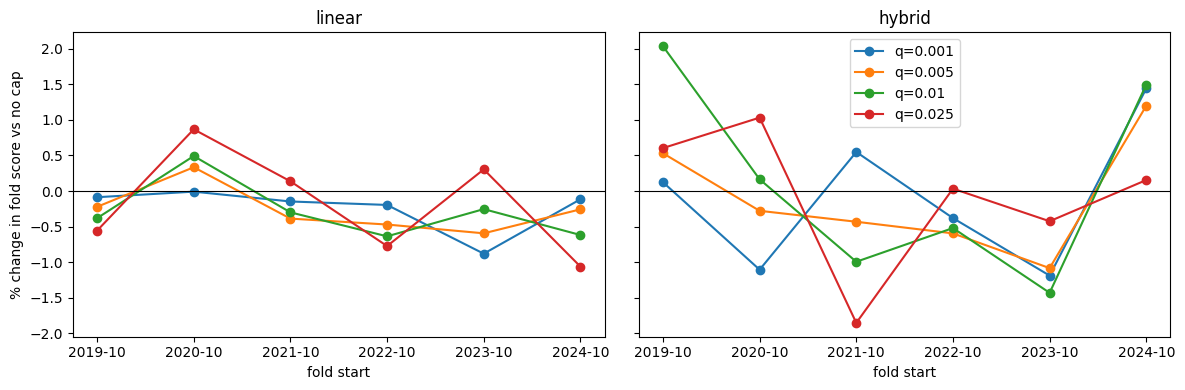

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, name in zip(axes, ("linear", "hybrid"), strict=True):
    for q in qs[1:]:
        change = 100 * (df[f"{name} q={q:g}"] / df[f"{name} q=0"] - 1)
        ax.plot(df.index, change, "o-", label=f"q={q:g}")
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(name)
    ax.set_xlabel("fold start")
axes[0].set_ylabel("% change in fold score vs no cap")
axes[1].legend()
plt.tight_layout()

## 3. The bounds, and how often the cap is active

In [4]:
bounds = {p.stem: json.loads(p.read_text(encoding="utf-8"))["bounds"]
          for p in sorted(rc.CACHE_DIR.glob("*.json"))}
rows = []
for year, b in bounds.items():
    for feat, (lo, hi) in b["0.005"].items():
        rows.append({"fold": year, "feature": feat, "low": lo, "high": hi})
display(pd.DataFrame(rows).pivot(index="feature", columns="fold", values=["low", "high"]).round(3))

low                                       high          \
fold                2019   2020   2021   2022   2023   2024    2019    2020   
feature                                                                       
bt_mean_1h         1.430  1.304  1.344  1.383  1.414  1.461  15.239  14.592   
ch_cm_at_24h       0.000  0.000  0.000  0.000  0.000  0.000   0.345   0.325   
density_mean_24h   0.272  0.228  0.238  0.228  0.221  0.228  12.818  12.818   
xray_peak_max_72h -7.000 -7.000 -7.000 -7.000 -7.000 -7.000  -4.043  -4.048   

                                                   
fold                 2021    2022    2023    2024  
feature                                            
bt_mean_1h         14.523  15.821  17.081  18.366  
ch_cm_at_24h        0.309   0.291   0.279   0.275  
density_mean_24h   12.736  12.727  12.544  12.847  
xray_peak_max_72h  -4.043  -3.822  -3.685  -3.198

In [5]:
from models.linear_model import LinearModel
from training import compare_history as ch

shipped = LinearModel.load()

data = ch.Data()
feats = list(shipped.config.features)
active = []
for start, end in rc.YEARLY:
    b = bounds[f"{start:%Y}"]["0.005"]
    x = data.x(data.fold(start, end)["t0s"], feats)
    lo = np.array([b[f][0] for f in feats])
    hi = np.array([b[f][1] for f in feats])
    row = {"fold": f"{start:%Y-%m}"}
    for j, f in enumerate(feats):
        ok = np.isfinite(x[:, j])
        row[f"{f} above"] = (x[ok, j] > hi[j]).mean()
        row[f"{f} below"] = (x[ok, j] < lo[j]).mean()
    active.append(row)
active = pd.DataFrame(active).set_index("fold")
with pd.option_context("display.float_format", "{:.2%}".format):
    display(active.loc[:, active.max() > 0])
print("shipped 9-year bounds (q=0.005):")
for f, lo, hi in zip(feats, shipped.x_low, shipped.x_high, strict=True):
    print(f"  {f:22s} [{lo:.3f}, {hi:.3f}]")

,bt_mean_1h above,bt_mean_1h below,ch_cm_at_24h above,xray_peak_max_72h above,density_mean_24h above,density_mean_24h below
fold,,,,,,
2019-10,0.07%,1.26%,0.00%,0.00%,0.48%,1.37%
2020-10,0.37%,0.30%,0.00%,0.82%,0.28%,0.35%
2021-10,2.20%,0.39%,0.00%,7.19%,0.70%,0.56%
2022-10,1.85%,0.15%,0.00%,3.22%,0.21%,0.76%
2023-10,2.07%,0.15%,0.00%,11.07%,1.35%,0.14%
2024-10,1.41%,0.14%,1.91%,0.00%,0.62%,1.16%


shipped 9-year bounds (q=0.005):
  bt_mean_1h             [1.469, 19.219]
  ch_cm_at_24h           [0.000, 0.284]
  xray_peak_max_72h      [-7.000, -3.235]
  density_mean_24h       [0.223, 12.873]


## 4. Findings

- **The cap helps a little and consistently.** At q = 0.005 the linear model gains 0.27% (5 of 6
  folds) and the hybrid 0.11% (4 of 6). Higher caps start to cost the hybrid (q = 0.01: +0.12%),
  because the trees already handle extremes and lose information when the anchor flattens them.
- **The gains are near fold-to-fold noise;** the main value is robustness. An input like the
  61 nT Bt is now taken at the cap (about 19 nT on nine years) instead of extrapolated.
- **Where the cap acts (q = 0.005, share of fold runs):** Bt above the cap in 0.1–2.2%,
  below it in 0.1–1.3%; density outside it in 0.1–1.4%. The X-ray flare peak is above the cap
  in 7.2% (2021 fold) and 11.1% (2023 fold) of runs: the years before those folds were near
  solar minimum, so the rising cycle's large flares were out of range. Its lower bound and the
  coronal-hole strip's are their floors (10⁻⁷ W/m², an empty strip), so they never act.
- **On nine years of history** the shipped bounds are wider (Bt 1.47–19.2 nT), since they now
  include the solar maximum.
- **Decision:** q = 0.005 is shipped (`training.linear_model.CAP_QUANTILE`, applied with the
  other data fixes); the linear model and the hybrid were retrained on the nine years. The eval
  year was not re-scored.